<a href="https://colab.research.google.com/github/Athul-Suresh-10/Unsupervised-case_study_athul-suresh/blob/main/Unsupervised_case_study_athul_suresh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [ ]:
# Load dataset

df = pd.read_csv('/content/drive/MyDrive/DSA 13/data set/adult_dataset.csv')

# Display first 5 rows
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [ ]:
# Shape
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Basic information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Shape: (48842, 15)

Columns:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

Data Types:
age               float64
workclass          object
fnlwgt              int64
education          object
education-num       int64
marital-status     object
occupation         object
relationship       object
race               object
sex                object
capital-gain        int64
capital-loss        int64
hours-per-week    float64
native-country     object
income             object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int6

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [ ]:
# Check missing values
print(df.isnull().sum())

age               2442
workclass         3362
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        3357
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week    2442
native-country    2705
income               0
dtype: int64


In [ ]:
# Identify numerical and categorical columns

numerical_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(exclude=np.number).columns

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

Categorical columns:
Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country', 'income'],
      dtype='object')


In [ ]:
# Fill numerical missing values with median

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with mode

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Check again
print(df.isnull().sum())

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64


In [ ]:
# Features specified in the case study

features = [
    'age',
    'fnlwgt',
    'education-num',
    'capital-gain',
    'capital-loss',
    'hours-per-week',
    'workclass',
    'education',
    'marital-status',
    'occupation',
    'relationship',
    'race',
    'sex',
    'native-country'
]

X = df[features].copy()

X.head()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass,education,marital-status,occupation,relationship,race,sex,native-country
0,39.0,77516,13,2174,0,40.0,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,United-States
1,50.0,83311,13,0,0,13.0,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States
2,38.0,215646,9,0,0,40.0,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States
3,53.0,234721,7,0,0,40.0,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States
4,28.0,338409,13,0,0,40.0,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba


In [ ]:
numeric_features = [
    'age',
    'fnlwgt',
    'education-num',
    'capital-gain',
    'capital-loss',
    'hours-per-week'
]

categorical_features = [
    'workclass',
    'education',
    'marital-status',
    'occupation',
    'relationship',
    'race',
    'sex',
    'native-country'
]

In [ ]:
X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True
)

print("Shape after encoding:", X_encoded.shape)

X_encoded.head()

Shape after encoding: (48842, 100)


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39.0,77516,13,2174,0,40.0,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,50.0,83311,13,0,0,13.0,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,38.0,215646,9,0,0,40.0,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False
3,53.0,234721,7,0,0,40.0,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False
4,28.0,338409,13,0,0,40.0,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
# Function to remove outliers using IQR

def remove_outliers_iqr(data, columns):
    data = data.copy()

    for col in columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        data = data[
            (data[col] >= lower_bound) &
            (data[col] <= upper_bound)
        ]

    return data

In [ ]:
# Remove outliers from numerical features

X_clean = remove_outliers_iqr(
    X_encoded,
    numeric_features
)

print("Original shape:", X_encoded.shape)
print("After outlier treatment:", X_clean.shape)

Original shape: (48842, 100)
After outlier treatment: (28884, 100)


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_clean)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (28884, 100)


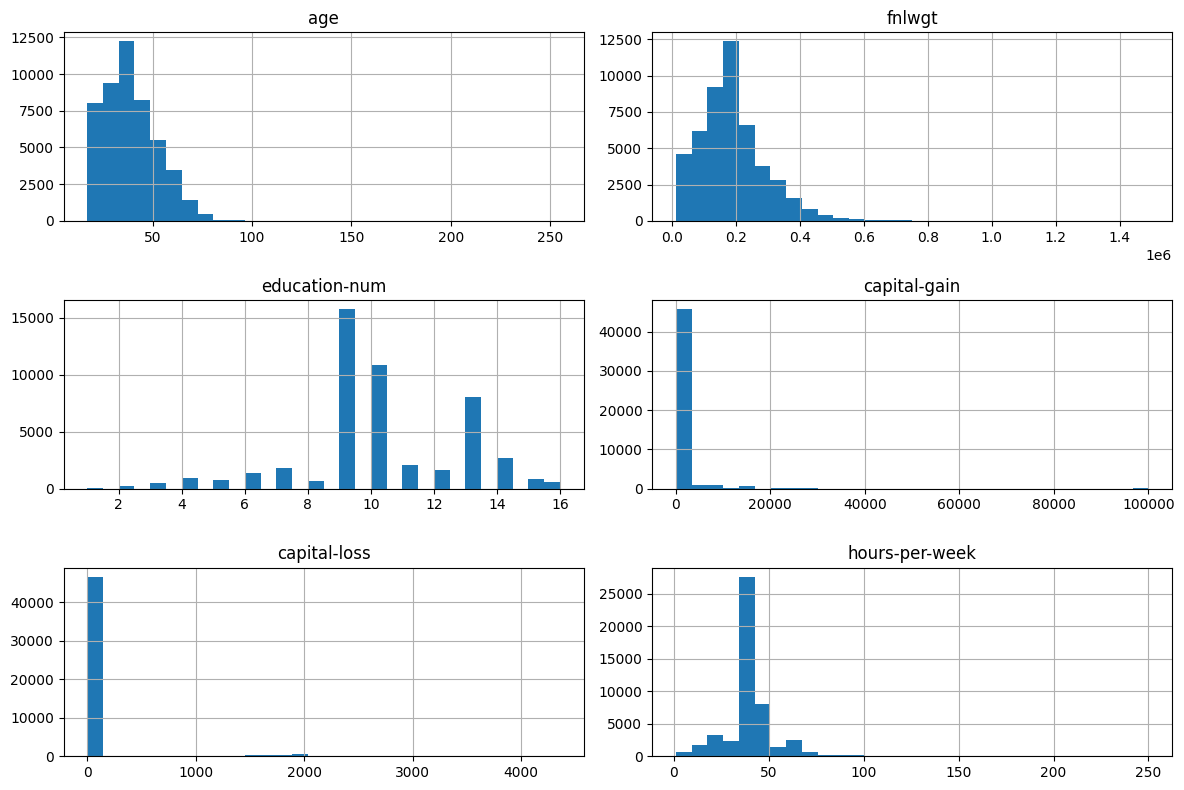

In [ ]:
# Plot numerical feature distributions

df[numeric_features].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

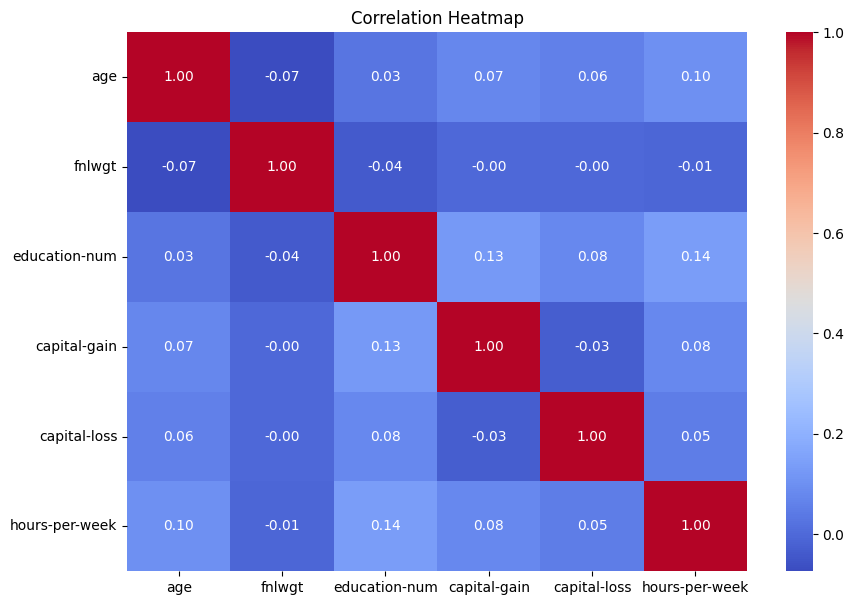

In [ ]:
plt.figure(figsize=(10, 7))

correlation = df[numeric_features].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("PCA shape:", X_pca.shape)

print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

PCA shape: (28884, 2)
Explained variance ratio:
[0.03387546 0.02927804]
Total explained variance: 0.06315349373520948


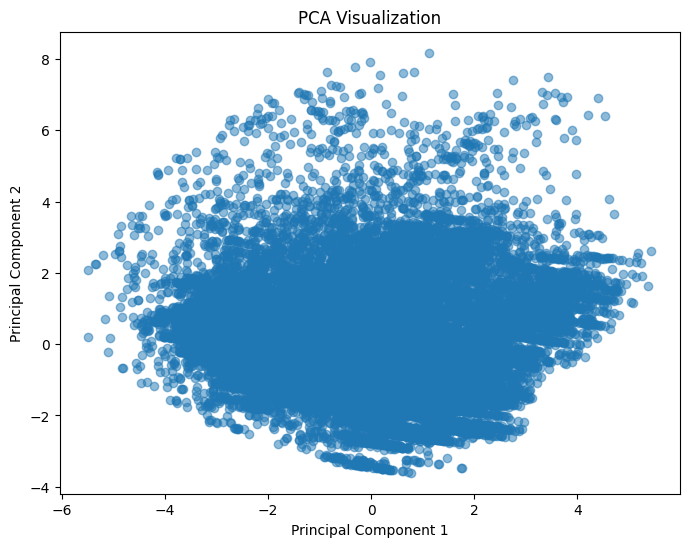

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization")

plt.show()

In [ ]:
inertia = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

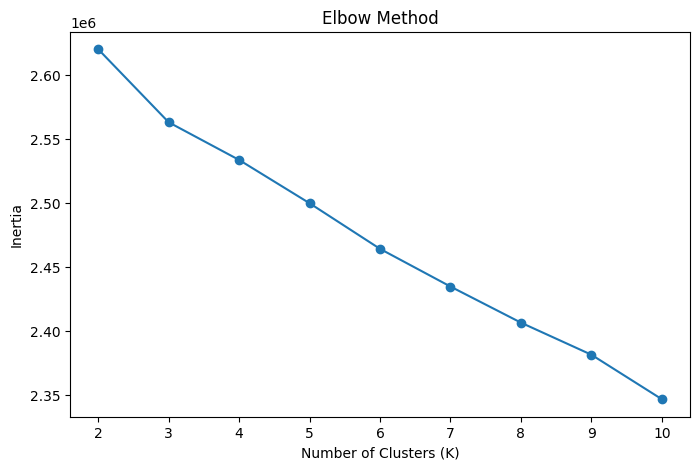

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    inertia,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [ ]:
silhouette_scores = []

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

    print(
        "K =", k,
        "Silhouette Score =", round(score, 4)
    )

K = 2 Silhouette Score = 0.0735
K = 3 Silhouette Score = 0.0266
K = 4 Silhouette Score = 0.0274
K = 5 Silhouette Score = 0.0389
K = 6 Silhouette Score = 0.0233
K = 7 Silhouette Score = 0.0257
K = 8 Silhouette Score = 0.0501
K = 9 Silhouette Score = 0.057
K = 10 Silhouette Score = 0.0344


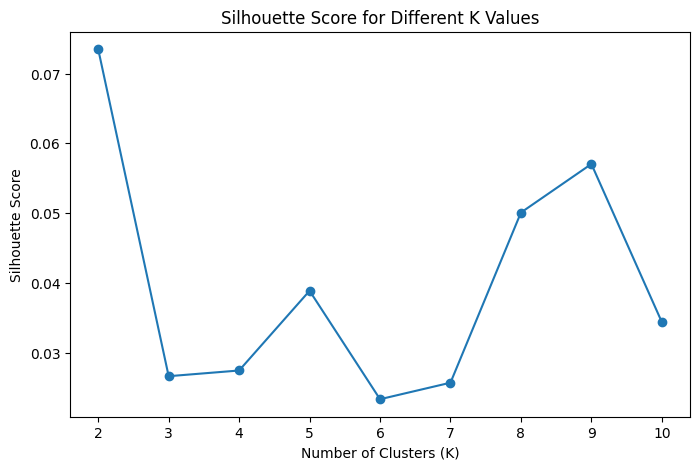

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    silhouette_scores,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.show()

In [ ]:
optimal_k = 4

In [ ]:
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed.")
X_clean = X_clean.copy()

X_clean['KMeans_Cluster'] = kmeans_labels

X_clean.head()

K-Means clustering completed.


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia,KMeans_Cluster
2,38.0,215646,9,0,0,40.0,False,False,False,True,...,False,False,False,False,False,False,True,False,False,1
3,53.0,234721,7,0,0,40.0,False,False,False,True,...,False,False,False,False,False,False,True,False,False,0
4,28.0,338409,13,0,0,40.0,False,False,False,True,...,False,False,False,False,False,False,False,False,False,0
5,37.0,284582,14,0,0,40.0,False,False,False,True,...,False,False,False,False,False,False,True,False,False,2
7,52.0,209642,9,0,0,45.0,False,False,False,False,...,False,False,False,False,False,False,True,False,False,2


In [ ]:
kmeans_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels
)

print(
    "K-Means Silhouette Score:",
    round(kmeans_silhouette, 4)
)

K-Means Silhouette Score: 0.0274


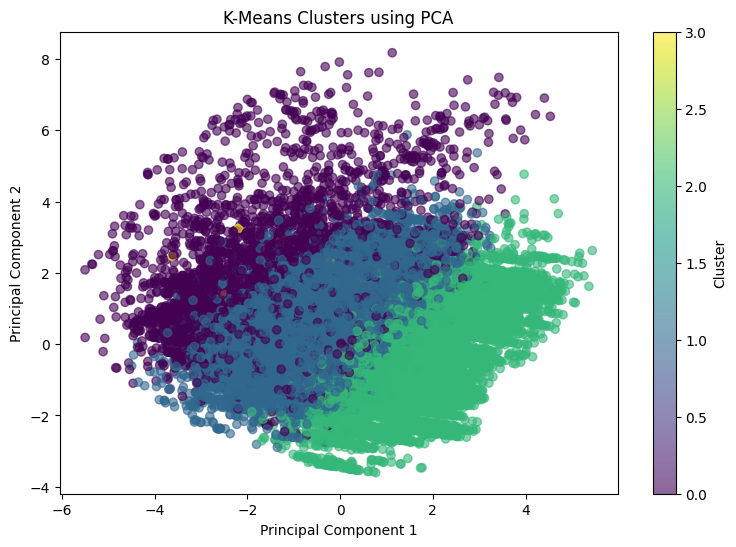

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters using PCA")

plt.colorbar(label="Cluster")

plt.show()

In [ ]:
agg = AgglomerativeClustering(
    n_clusters=optimal_k
)

agg_labels = agg.fit_predict(X_scaled)

print("Agglomerative clustering completed.")

Agglomerative clustering completed.


In [ ]:
agg_silhouette = silhouette_score(
    X_scaled,
    agg_labels
)

print(
    "Agglomerative Silhouette Score:",
    round(agg_silhouette, 4)
)

Agglomerative Silhouette Score: 0.0061


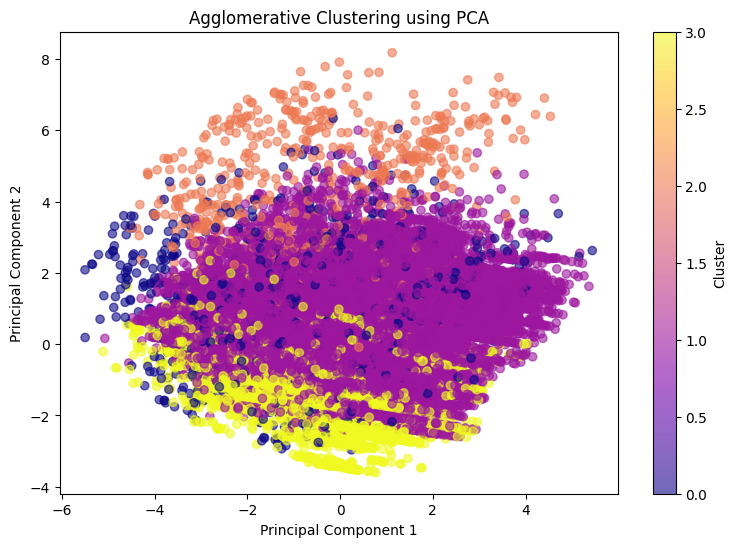

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=agg_labels,
    cmap='plasma',
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Agglomerative Clustering using PCA")

plt.colorbar(label="Cluster")

plt.show()

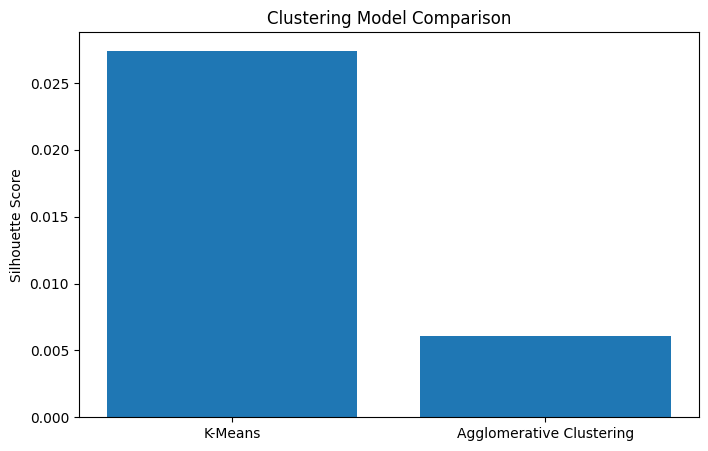

In [ ]:
comparison = pd.DataFrame({
    'Model': [
        'K-Means',
        'Agglomerative Clustering'
    ],
    'Silhouette Score': [
        kmeans_silhouette,
        agg_silhouette
    ]
})

comparison
plt.figure(figsize=(8, 5))

plt.bar(
    comparison['Model'],
    comparison['Silhouette Score']
)

plt.ylabel("Silhouette Score")
plt.title("Clustering Model Comparison")

plt.show()

In [ ]:
# Use the cleaned rows corresponding to X_clean

clustered_data = X_clean.copy()

clustered_data['Cluster'] = kmeans_labels

clustered_data.head()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia,KMeans_Cluster,Cluster
2,38.0,215646,9,0,0,40.0,False,False,False,True,...,False,False,False,False,False,True,False,False,1,1
3,53.0,234721,7,0,0,40.0,False,False,False,True,...,False,False,False,False,False,True,False,False,0,0
4,28.0,338409,13,0,0,40.0,False,False,False,True,...,False,False,False,False,False,False,False,False,0,0
5,37.0,284582,14,0,0,40.0,False,False,False,True,...,False,False,False,False,False,True,False,False,2,2
7,52.0,209642,9,0,0,45.0,False,False,False,False,...,False,False,False,False,False,True,False,False,2,2


Cluster
0     4160
1    12874
2    11831
3       19
Name: count, dtype: int64


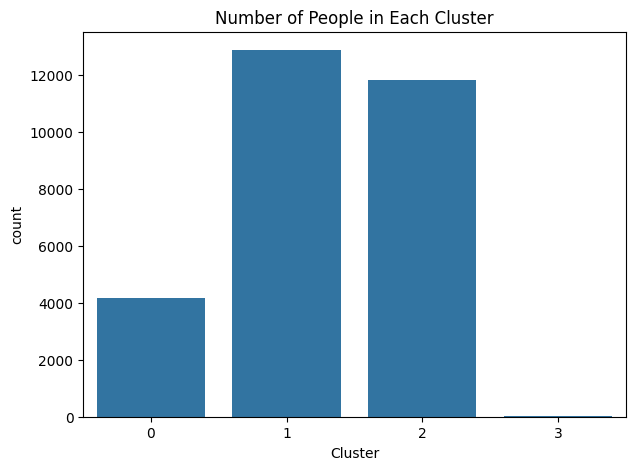

In [ ]:
print(
    clustered_data['Cluster'].value_counts().sort_index()
)
plt.figure(figsize=(7, 5))

sns.countplot(
    x='Cluster',
    data=clustered_data
)

plt.title("Number of People in Each Cluster")
plt.show()

In [ ]:
cluster_profile = clustered_data.groupby(
    'Cluster'
)[numeric_features].mean()

cluster_profile

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
Cluster,,,,,,
0,37.248798,194016.038702,10.028846,0.0,0.0,40.386779
1,34.459842,180522.240096,10.166848,0.0,0.0,40.897468
2,41.871947,175654.282394,10.400051,0.0,0.0,42.098301
3,33.421053,194731.842105,10.315789,0.0,0.0,41.052632


In [ ]:
categorical_profile = {}

for col in categorical_features:

    categorical_profile[col] = (
        X.loc[clustered_data.index]
        .groupby(clustered_data['Cluster'])[col]
        .agg(lambda x: x.mode()[0])
    )

categorical_profile = pd.DataFrame(
    categorical_profile
)

categorical_profile

,workclass,education,marital-status,occupation,relationship,race,sex,native-country
Cluster,,,,,,,,
0,Private,HS-grad,Never-married,Prof-specialty,Not-in-family,Black,Male,United-States
1,Private,HS-grad,Never-married,Prof-specialty,Not-in-family,White,Female,United-States
2,Private,HS-grad,Married-civ-spouse,Craft-repair,Husband,White,Male,United-States
3,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,Ecuador


In [ ]:
income_comparison = df.loc[
    clustered_data.index
].copy()

income_comparison['Cluster'] = clustered_data['Cluster']

income_comparison.groupby(
    'Cluster'
)['income'].value_counts()
income_percentage = pd.crosstab(
    income_comparison['Cluster'],
    income_comparison['income'],
    normalize='index'
) * 100

income_percentage

income,<=50K,<=50K.,>50K,>50K.
Cluster,,,,
0,58.629808,28.365385,8.605769,4.399038
1,62.700016,32.305422,3.394438,1.600124
2,39.371144,19.482715,27.453301,13.692841
3,52.631579,26.315789,15.789474,5.263158


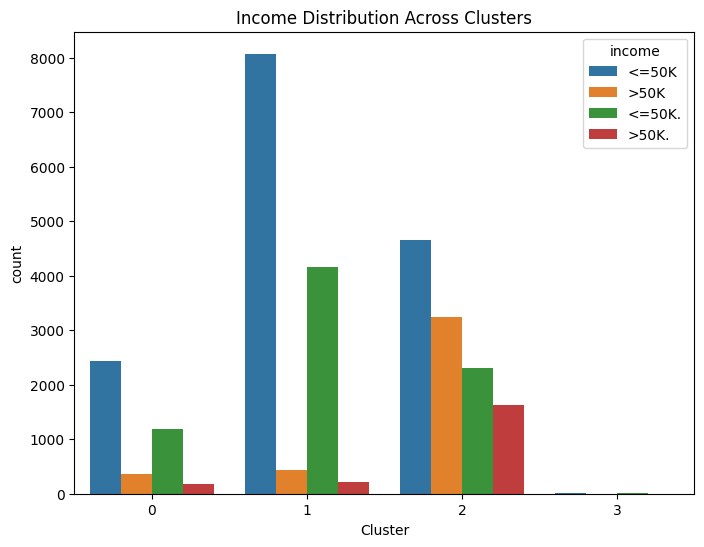

In [ ]:
plt.figure(figsize=(8, 6))

sns.countplot(
    data=income_comparison,
    x='Cluster',
    hue='income'
)

plt.title("Income Distribution Across Clusters")
plt.show()

In [ ]:
cluster_comparison = pd.DataFrame({
    'KMeans': kmeans_labels,
    'Agglomerative': agg_labels
})

cluster_comparison.head()

,KMeans,Agglomerative
0,1,3
1,0,3
2,0,0
3,2,1
4,2,1


In [ ]:
final_summary = clustered_data.groupby(
    'Cluster'
).agg(
    Average_Age=('age', 'mean'),
    Average_Education_Num=('education-num', 'mean'),
    Average_Hours_Per_Week=('hours-per-week', 'mean'),
    Average_Capital_Gain=('capital-gain', 'mean'),
    Average_Capital_Loss=('capital-loss', 'mean'),
    Number_of_People=('age', 'count')
)

final_summary

,Average_Age,Average_Education_Num,Average_Hours_Per_Week,Average_Capital_Gain,Average_Capital_Loss,Number_of_People
Cluster,,,,,,
0,37.248798,10.028846,40.386779,0.0,0.0,4160
1,34.459842,10.166848,40.897468,0.0,0.0,12874
2,41.871947,10.400051,42.098301,0.0,0.0,11831
3,33.421053,10.315789,41.052632,0.0,0.0,19


In [ ]:
clustered_data.to_csv(
    '/content/clustered_adult_data.csv',
    index=False
)

print("Clustered dataset saved successfully.")

Clustered dataset saved successfully.
